# Lược đồ màu HSV + kNN

**Mục tiêu:** phân loại 43 lớp GTSRB chỉ dựa trên màu sắc để làm đối chứng.
Pipeline: ảnh BGR → resize 64×64 → HSV → histogram 3D → chuẩn hóa L1 → kNN.


## 1. Thư viện và dữ liệu dùng chung

Nếu thiếu thư viện, bỏ dấu `#` ở dòng cài đặt và chạy một lần.
Không chia lại dữ liệu; dùng các CSV do người 1 chốt theo track.

In [1]:
# %pip install numpy pandas opencv-python matplotlib scikit-learn joblib threadpoolctl

from pathlib import Path
import sys
import json
import inspect
import joblib
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from threadpoolctl import threadpool_limits

PROJECT = Path.cwd()
if PROJECT.name == "code":
    PROJECT = PROJECT.parent
sys.path.insert(0, str(PROJECT / "code"))

from preprocessing import read_bgr, preprocess
from features_hsv import hsv_histogram, predict_hsv
from train_hsv import run_training

DATA = PROJECT / "data/raw"
OUTPUT = PROJECT / "results/hsv"
OUTPUT.mkdir(parents=True, exist_ok=True)
train = pd.read_csv(PROJECT / "splits/train.csv", keep_default_na=False)
validation = pd.read_csv(PROJECT / "splits/validation.csv", keep_default_na=False)
names = pd.read_csv(PROJECT / "configs/class_names.csv").set_index("class_id")

assert not (set(train.track_id) & set(validation.track_id))
print("Số ảnh train:", len(train))
print("Số ảnh validation:", len(validation))
print("Không đọc tập test.")

def table_html(html):
    import re
    html = re.sub(r"<style.*?</style>", "", html, flags=re.DOTALL)
    header = "color:#172b4d !important;background:#e8eef5 !important;padding:8px 12px;border:1px solid #ccd5df;white-space:nowrap;"
    body = "color:#172b4d !important;background:#ffffff !important;padding:8px 12px;border:1px solid #ccd5df;white-space:nowrap;"
    html = re.sub(r"<th(?=[ >])", '<th style="' + header + '"', html)
    html = re.sub(r"<td(?=[ >])", '<td style="' + body + '"', html)
    html = html.replace("<table ", '<table style="border-collapse:collapse;font-family:Arial,sans-serif;font-size:13px;" ')
    return '<div style="background:#fff;color:#172b4d;padding:10px;max-width:100%;overflow-x:auto;">' + html + '</div>'


def show_table(table):
    # Series (một cột) được chuyển thành bảng trước khi hiển thị.
    if isinstance(table, pd.Series):
        table = table.to_frame(name="Giá trị")
    display(HTML(table_html(table.to_html(border=0))))


Số ảnh train: 31380
Số ảnh validation: 7829
Không đọc tập test.


## 2. Histogram HSV là gì?

HSV gồm H (sắc màu), S (độ bão hòa), V (độ sáng).
Histogram **3D** đếm số pixel rơi vào mỗi tổ hợp bin H–S–V, rồi trải thành vector một chiều.
Ví dụ `(8,4,4)` tạo `8 × 4 × 4 = 128` đặc trưng; `(16,4,4)` tạo 256 đặc trưng.

Chuẩn hóa L1: chia mỗi ô cho tổng số pixel, nên tổng vector bằng 1.
Đây là phép chuẩn hóa **riêng từng ảnh**, không dùng thống kê validation/test và không cần scaler học tham số.
Không dùng StandardScaler trong cấu hình này để giữ ý nghĩa tỉ lệ pixel của histogram.

OpenCV uint8: miền H `[0,180)`, S/V `[0,256)`, bao gồm cả giá trị S/V=255.
Histogram toàn ảnh bỏ qua vị trí pixel: hai ảnh cùng màu nhưng khác ký hiệu có thể rất giống nhau.

Đây là hàm thật được dùng khi huấn luyện và dự đoán:

In [2]:
print(inspect.getsource(hsv_histogram))

def hsv_histogram(image, bins=(8, 4, 4), size=(64, 64)):
    """Histogram HSV 3 chiều, trải phẳng và chuẩn hóa tổng bằng 1."""
    if len(bins) != 3 or any(int(b) != b or b < 1 for b in bins):
        raise ValueError('bins cần có 3 số nguyên dương: H, S, V')
    hsv = preprocess(image, size=size, color='hsv')
    histogram = cv2.calcHist(
        [hsv], [0, 1, 2], None, list(map(int, bins)),
        [0, 180, 0, 256, 0, 256],
    )
    vector = histogram.flatten()
    return vector / vector.sum()  # Chuẩn hóa L1 riêng từng ảnh, không cần fit scaler.



## 3. Minh họa ảnh và đặc trưng màu

Chọn một ảnh train của lớp STOP với kích thước lớn để quan sát.
Ba biểu đồ phía dưới chỉ minh họa lược đồ **từng kênh**;
bộ phân loại thực tế dùng histogram **3D chung**, không ghép ba histogram này.

Vector có 128 chiều; tổng = 1.0


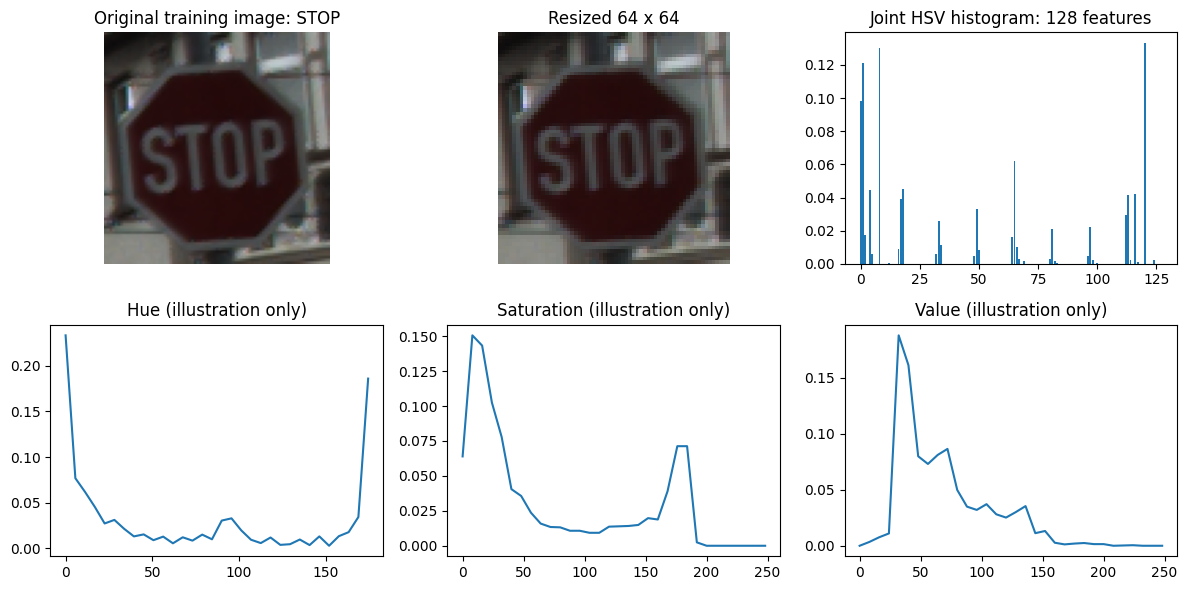

In [3]:
stop_images = train.query("class_id == 14")
# Lấy một nhóm nhỏ cuối danh sách để tìm ảnh gốc lớn, chỉ nhằm minh họa.
candidates = []
for path in stop_images.sort_values("path").tail(30).path:
    image = read_bgr(DATA / path)
    candidates.append((image.shape[0] * image.shape[1], path, image))
_, example_path, image = max(candidates, key=lambda item: item[0])
hsv = preprocess(image, color="hsv")
vector = hsv_histogram(image, bins=(8, 4, 4))
print("Vector có", len(vector), "chiều; tổng =", float(vector.sum()))

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
axes[0, 0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0, 0].set_title("Original training image: STOP")
axes[0, 1].imshow(preprocess(image, color="rgb"))
axes[0, 1].set_title("Resized 64 x 64")
axes[0, 2].bar(np.arange(len(vector)), vector)
axes[0, 2].set_title("Joint HSV histogram: 128 features")
for ax in axes[0, :2]:
    ax.axis("off")
for channel, title in enumerate(["Hue", "Saturation", "Value"]):
    upper = 180 if channel == 0 else 256
    hist = cv2.calcHist([hsv], [channel], None, [32], [0, upper]).ravel()
    axes[1, channel].plot(np.linspace(0, upper, 32, endpoint=False), hist / hist.sum())
    axes[1, channel].set_title(title + " (illustration only)")
plt.tight_layout()
plt.savefig(OUTPUT / "hsv_example.png", dpi=150)
plt.show()

## 4. Chọn cấu hình bằng validation

- Bins: `(8,4,4)`, `(16,4,4)`.
- k: `3, 5, 7`.
- Khoảng cách: Euclidean và Manhattan.
- Bỏ phiếu đồng đều (`uniform`), resize 64×64 cố định, tìm láng giềng bằng brute force.

Tổng **12 cấu hình**. Cần dùng cùng ngân sách tìm kiếm 12 cấu hình cho HOG và kết hợp trong so sánh chung.
Ưu tiên Macro-F1 vì phân bố lớp mất cân bằng; hòa thì chọn Accuracy cao hơn,
số chiều ít hơn, k nhỏ hơn rồi thứ tự khoảng cách trong grid. Không chọn theo test hoặc tốc độ.

Đặt `RUN_TRAINING = True` để huấn luyện lại đầy đủ (có thể mất vài phút).
Nếu chưa có kết quả, notebook tự chạy lần đầu. Khi chạy lại, mô hình và kết quả **HSV** sẽ được thay thế;
các split không đổi. kNN gần như chỉ lưu mẫu khi fit, chi phí chủ yếu ở dự đoán.

In [4]:
RUN_TRAINING = False
if RUN_TRAINING or not (OUTPUT / "summary.json").exists():
    summary = run_training(PROJECT)
else:
    summary = json.loads((OUTPUT / "summary.json").read_text(encoding="utf-8"))
    print("Dùng kết quả validation đã chạy; bật RUN_TRAINING để chạy lại.")

# Đảm bảo kết quả đang xem đúng các split hiện tại.
import hashlib
for name, expected_hash in summary["split_sha256"].items():
    actual = hashlib.sha256((PROJECT / f"splits/{name}.csv").read_bytes()).hexdigest()
    assert actual == expected_hash, "Split đã thay đổi; cần chạy lại huấn luyện"
assert summary["test_evaluated"] is False

Dùng kết quả validation đã chạy; bật RUN_TRAINING để chạy lại.


## 5. Bảng kết quả validation thực tế

Các điểm số bên dưới lấy từ lần chạy thật; **không phải kết quả test**.
Thời gian kNN là một lượt dự đoán cả validation, chia số ảnh.
Thời gian toàn luồng còn gồm đọc ảnh, resize, HSV và histogram L1; không phải latency một ảnh đo lặp.
Trích đặc trưng được tái sử dụng khi chỉ đổi k/khoảng cách.

,h_bins,s_bins,v_bins,k,distance,n_features,accuracy,macro_f1,classifier_ms_per_image,end_to_end_ms_per_image
7,16,4,4,3,manhattan,256,0.1745,0.1341,2.4781,2.8828
9,16,4,4,5,manhattan,256,0.1751,0.1330,2.7310,3.1357
11,16,4,4,7,manhattan,256,0.1740,0.1326,2.3743,2.7790
1,8,4,4,3,manhattan,128,0.1626,0.1308,1.6385,2.3768
3,8,4,4,5,manhattan,128,0.1621,0.1307,1.2896,2.0279
5,8,4,4,7,manhattan,128,0.1622,0.1273,1.2336,1.9719
8,16,4,4,5,euclidean,256,0.1569,0.1226,0.2626,0.6673
6,16,4,4,3,euclidean,256,0.1574,0.1215,0.2378,0.6425
10,16,4,4,7,euclidean,256,0.1551,0.1195,0.2820,0.6867
2,8,4,4,5,euclidean,128,0.1471,0.1150,0.3162,1.0545


Cấu hình tốt nhất:


,Giá trị
h_bins,16
s_bins,4
v_bins,4
k,3
distance,manhattan
weights,uniform
n_features,256
accuracy,0.174479
macro_f1,0.134065
train_feature_seconds,11.31388


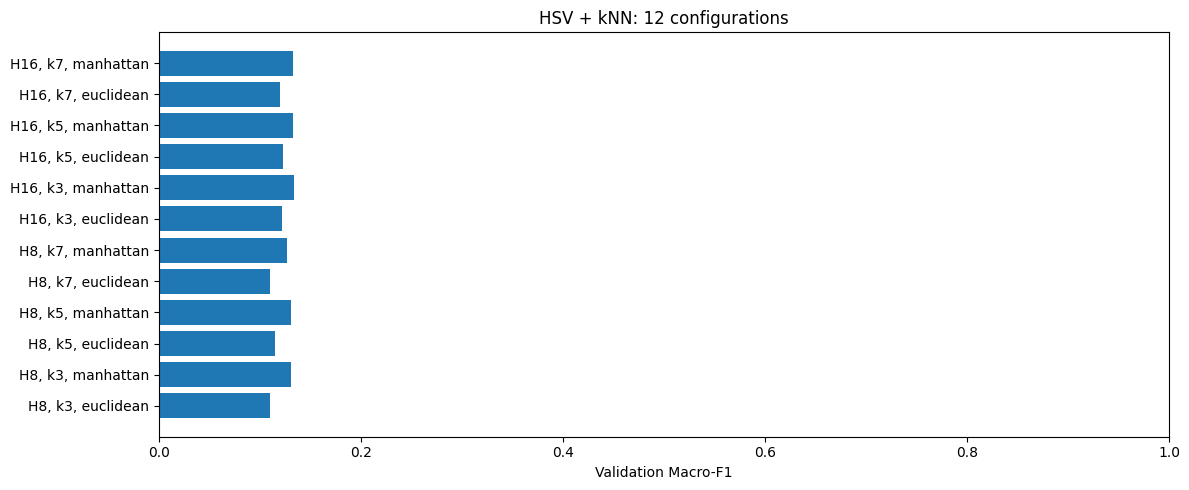

In [5]:
results = pd.read_csv(OUTPUT / "validation_results.csv")
ranked = results.sort_values(
    ["macro_f1", "accuracy", "n_features", "k"], ascending=[False, False, True, True]
)
columns = ["h_bins", "s_bins", "v_bins", "k", "distance", "n_features",
           "accuracy", "macro_f1", "classifier_ms_per_image", "end_to_end_ms_per_image"]
show_table(ranked[columns].round(4))
print("Cấu hình tốt nhất:")
show_table(pd.Series(summary["best"]))

labels = [f"H{r.h_bins}, k{r.k}, {r.distance}" for r in results.itertuples()]
plt.figure(figsize=(12, 5))
plt.barh(labels, results.macro_f1)
plt.xlabel("Validation Macro-F1")
plt.title("HSV + kNN: 12 configurations")
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig(OUTPUT / "validation_search.png", dpi=150)
plt.show()

## 6. Nạp mô hình và dự đoán một ảnh

File lưu cả kNN, số bin, kích thước ảnh, quy tắc chuẩn hóa và tên lớp.
Hàm dự đoán dùng lại đúng `hsv_histogram`. Không hiển thị phiếu bầu thành xác suất chính xác.
Mô hình chỉ được fit trên train, chưa gộp validation để huấn luyện lại.

Nhãn thật: 0 Giới hạn tốc độ 20 km/h
Dự đoán: 13 Nhường đường


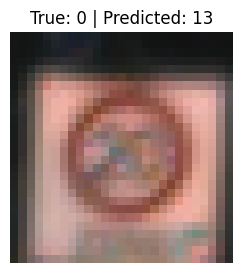

In [6]:
bundle = joblib.load(PROJECT / "models/hsv_knn.joblib")
row = validation.iloc[0]
image = read_bgr(DATA / row.path)
with threadpool_limits(limits=4):
    predicted = predict_hsv(bundle, image)
print("Nhãn thật:", row.class_id, names.loc[row.class_id, "name_vi"])
print("Dự đoán:", predicted, names.loc[predicted, "name_vi"])
plt.figure(figsize=(3, 3))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title(f"True: {row.class_id} | Predicted: {predicted}")
plt.axis("off")
plt.show()

## 7. Xem cả dự đoán đúng và sai

Lấy 3 ảnh đúng và 3 ảnh sai đầu tiên theo thứ tự CSV, không chọn chỉ các ảnh đẹp.
Các ảnh dùng để phân tích định tính, không đại diện toàn bộ validation.
Quan sát biển cùng màu nhưng khác số/ký hiệu, ảnh tối, mờ và phần nền còn trong crop.

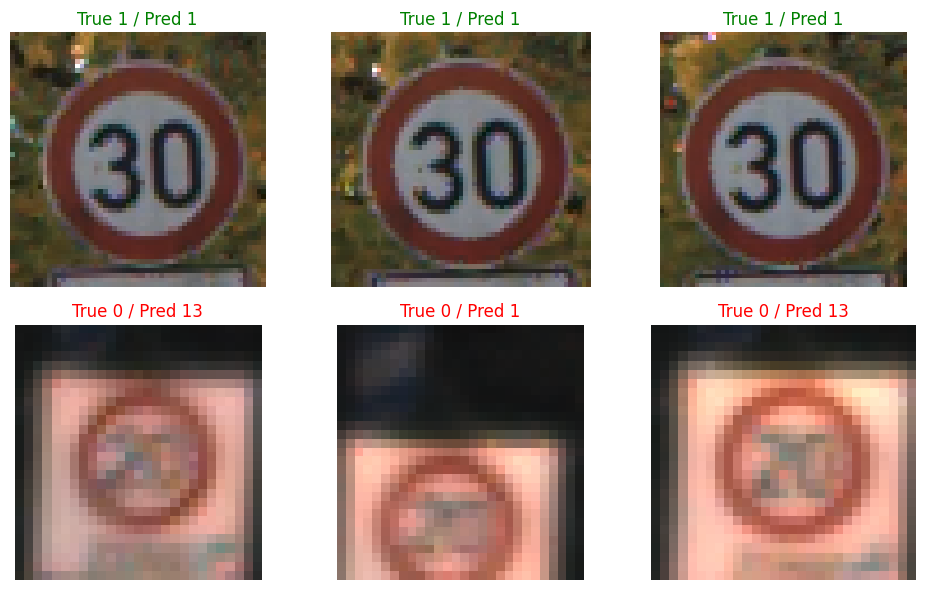

,,number_of_errors
true_class,predicted_class,
4,2,86
38,35,83
8,10,75
35,38,72
5,4,67
1,2,65
34,35,64
13,2,62
10,5,58


,class_id,precision,recall,f1-score,support
0,0,0.0000,0.0000,0.0000,30.0
1,1,0.1268,0.1756,0.1473,450.0
2,2,0.0789,0.1044,0.0899,450.0
3,3,0.1692,0.2481,0.2012,270.0
4,4,0.0786,0.1410,0.1009,390.0
5,5,0.1277,0.1472,0.1368,360.0
6,6,0.2817,0.2222,0.2484,90.0
7,7,0.2343,0.3100,0.2669,300.0
8,8,0.1715,0.1741,0.1728,270.0
9,9,0.0642,0.0567,0.0602,300.0


In [7]:
predictions = pd.read_csv(OUTPUT / "validation_predictions.csv")
examples = pd.concat([
    predictions[predictions.correct].head(3),
    predictions[~predictions.correct].head(3),
])
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax in axes.flat:
    ax.axis("off")
for ax, row in zip(axes.flat, examples.itertuples()):
    image = read_bgr(DATA / row.path)
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(f"True {row.true_class} / Pred {row.predicted_class}",
                 color="green" if row.correct else "red")
plt.tight_layout()
plt.savefig(OUTPUT / "validation_examples.png", dpi=150)
plt.show()

wrong = predictions[~predictions.correct]
confused_pairs = wrong.groupby(["true_class", "predicted_class"]).size().sort_values(ascending=False)
show_table(confused_pairs.head(10).rename("number_of_errors").to_frame())
show_table(pd.read_csv(OUTPUT / "validation_per_class.csv").round(4))

## 8. Bàn giao

- `features_hsv.py`: `hsv_histogram` để người 4 ghép với HOG; `predict_hsv` để dùng mô hình.
- `train_hsv.py`: chạy grid validation và lưu mô hình, không đọc test.
- `evaluation.py`: Accuracy, Macro-F1 và Precision/Recall/F1 từng lớp dùng chung.
- `models/hsv_knn.joblib`: kNN train-only với cấu hình HSV và tên lớp.
- `results/hsv/`: bảng 12 cấu hình, dự đoán từng ảnh validation, chỉ số từng lớp, summary và hình minh họa.
- `reports/hsv_knn.md`: phần báo cáo phương pháp màu và số liệu thực tế.


**Cập nhật:** đánh giá test chung sau khi khóa ba phương pháp nằm ở `04_hsv_hog_knn.ipynb`. Các bảng trong notebook này là kết quả validation của giai đoạn chọn tham số.